# RQ6 — What is the full geometry of the supervised $R\times S$ generalization surface?

## Scientific question

**How much predictive performance is retained as redundancy control (`R`) and train–test homology separation (`S`) jointly become stricter, and what geometric properties characterize the complete 16-cell generalization surface of each model?**

For every frozen supervised model family

\[
\text{task}\times\text{representation}\times\text{algorithm},
\]

we observe the complete surface

\[
M(R,S),\qquad R,S\in\{90,70,50,30\}.
\]

RQ6 complements the axis-specific RQ2/RQ3 analyses and the formal interaction analysis in RQ4 by treating each 4×4 grid as a **single generalization landscape**.

The principal degradation quantity is defined relative to the permissive reference condition:

\[
D(R,S)=M(R,S)-M(90,90).
\]

Thus, `D < 0` denotes performance loss relative to `R90/S90`, `D = 0` denotes no change, and `D > 0` denotes improvement.


## Scope and interpretation contract

This notebook is deliberately restricted to **surface geometry**.

It answers:

1. What does the complete `M(R,S)` landscape look like for every model family?
2. How much performance is lost or retained relative to `R90/S90` across all 16 cells?
3. How different are tasks, representations, and learners in strict-corner retention and overall degradation burden?
4. How smooth or irregular are the surfaces when moving one adjacent R or S step at a time?
5. Which cells most frequently constitute the best and worst points of a surface?
6. Are the MCC degradation patterns qualitatively preserved with AP-skill for binary tasks and macro-F1 for multiclass?

### Guardrails

- **MCC is the primary supervised metric.**
- Native test membership can differ across R and/or S. Therefore `D(R,S)` is a **factorial native-test contrast**, not an entity-level paired effect.
- Common-test sensitivity belongs to RQ18 and is not re-estimated here.
- RQ6 does **not** classify early/mid/late breakpoints (RQ20), mixed joint trajectories (RQ21), or deployment robustness (RQ17/RQ26).
- No training, bootstrap, or prediction regeneration is performed. This notebook only consumes frozen Stage12A outputs.


In [1]:
from pathlib import Path
import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]
PRIMARY_METRIC = "mcc"
MONOTONIC_TOL = 0.005

TASK_ORDER = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
    "multiclass_clean",
]

REP_ORDER = [
    "roxy_48",
    "onehot_1024",
    "esm2_t6_8m",
    "esm2_t30_150m",
]

ALG_ORDER = ["KNN", "LR", "MLP", "RF", "XGB"]

BINARY_TASKS = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        master = candidate / "results/analysis_supervised/stage12a/supervised_master_results.tsv"
        if master.is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the PhageLysClass project root containing "
        "results/analysis_supervised/stage12a/supervised_master_results.tsv"
    )


ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
CACHE_ROOT = ROOT / "results/analysis_supervised/notebook_cache"
RQ6_OUT = CACHE_ROOT / "rq6_surface_geometry"
FIG_DIR = RQ6_OUT / "figures"
RQ6_OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("RQ6_OUT:", RQ6_OUT)
print("No model training or prediction regeneration is performed in RQ6.")

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
RQ6_OUT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq6_surface_geometry
No model training or prediction regeneration is performed in RQ6.


## 1. Load the frozen supervised benchmark and validate the 4×4 factorial

In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

required = {"task", "R", "S", "representation", "algorithm", PRIMARY_METRIC}
missing = required - set(master.columns)
if missing:
    raise KeyError(f"supervised_master_results.tsv missing required columns: {sorted(missing)}")

for c in ["R", "S", PRIMARY_METRIC]:
    master[c] = pd.to_numeric(master[c], errors="coerce")

if master[["R", "S"]].isna().any().any():
    raise ValueError("R or S contains non-numeric / missing values.")

master["R"] = master["R"].astype(int)
master["S"] = master["S"].astype(int)

observed_tasks = list(master["task"].dropna().astype(str).unique())
observed_reps = list(master["representation"].dropna().astype(str).unique())
observed_algs = list(master["algorithm"].dropna().astype(str).unique())

TASKS = [x for x in TASK_ORDER if x in observed_tasks] + sorted(set(observed_tasks) - set(TASK_ORDER))
REPS = [x for x in REP_ORDER if x in observed_reps] + sorted(set(observed_reps) - set(REP_ORDER))
ALGS = [x for x in ALG_ORDER if x in observed_algs] + sorted(set(observed_algs) - set(ALG_ORDER))

assert set(master["R"].unique()) == set(R_LEVELS), f"Unexpected R levels: {sorted(master['R'].unique())}"
assert set(master["S"].unique()) == set(S_LEVELS), f"Unexpected S levels: {sorted(master['S'].unique())}"

key_cols = ["task", "representation", "algorithm", "R", "S"]
if master.duplicated(key_cols).any():
    dup = master.loc[master.duplicated(key_cols, keep=False), key_cols].sort_values(key_cols)
    raise ValueError("Duplicate supervised cells detected:\n" + dup.head(30).to_string(index=False))

coverage = (
    master.groupby(["task", "representation", "algorithm"], as_index=False)
    .agg(
        n_cells=(PRIMARY_METRIC, "size"),
        n_unique_R=("R", "nunique"),
        n_unique_S=("S", "nunique"),
        n_metric=(PRIMARY_METRIC, "count"),
    )
)

n_expected_surfaces = len(TASKS) * len(REPS) * len(ALGS)
n_expected_rows = n_expected_surfaces * 16

print("Rows:", len(master), "/ expected", n_expected_rows)
print("Tasks:", TASKS)
print("Representations:", REPS)
print("Algorithms:", ALGS)
print("Surfaces:", len(coverage), "/ expected", n_expected_surfaces)
display(coverage["n_cells"].value_counts().sort_index().rename("n_surfaces").to_frame())

assert len(coverage) == n_expected_surfaces, "Unexpected number of task×representation×algorithm surfaces."
assert coverage["n_cells"].eq(16).all(), "At least one model family lacks one or more R×S cells."
assert coverage["n_unique_R"].eq(4).all() and coverage["n_unique_S"].eq(4).all(), "Incomplete R or S levels detected."
assert coverage["n_metric"].eq(16).all(), "At least one surface contains missing MCC values."
assert len(master) == n_expected_rows, "Unexpected number of supervised families."

print("FACTORIAL_COVERAGE_OK")

Rows: 2240 / expected 2240
Tasks: ['global_easy', 'global_hard', 'global_mixed', 'subtype_endolysin', 'subtype_depolymerase', 'subtype_val', 'multiclass_clean']
Representations: ['roxy_48', 'onehot_1024', 'esm2_t6_8m', 'esm2_t30_150m']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']
Surfaces: 140 / expected 140


,n_surfaces
n_cells,
16,140


FACTORIAL_COVERAGE_OK


## 2. Construct cell-wise surface geometry relative to `R90/S90`

In [3]:
group_cols = ["task", "representation", "algorithm"]

baseline = (
    master.loc[master["R"].eq(90) & master["S"].eq(90), group_cols + [PRIMARY_METRIC]]
    .rename(columns={PRIMARY_METRIC: "baseline_mcc"})
)

assert len(baseline) == n_expected_surfaces, "Every surface must contain exactly one R90/S90 baseline."

surface_cells = master[group_cols + ["R", "S", PRIMARY_METRIC]].merge(
    baseline,
    on=group_cols,
    how="left",
    validate="many_to_one",
)

surface_cells["delta_from_R90S90"] = surface_cells[PRIMARY_METRIC] - surface_cells["baseline_mcc"]
surface_cells["loss_from_R90S90"] = surface_cells["baseline_mcc"] - surface_cells[PRIMARY_METRIC]
surface_cells["retention_fraction"] = np.where(
    surface_cells["baseline_mcc"] > 0,
    surface_cells[PRIMARY_METRIC] / surface_cells["baseline_mcc"],
    np.nan,
)
surface_cells["cell"] = "R" + surface_cells["R"].astype(str) + "_S" + surface_cells["S"].astype(str)
surface_cells["is_baseline"] = surface_cells["R"].eq(90) & surface_cells["S"].eq(90)
surface_cells["is_strict_corner"] = surface_cells["R"].eq(30) & surface_cells["S"].eq(30)

baseline_check = surface_cells.loc[surface_cells["is_baseline"], "delta_from_R90S90"]
assert np.allclose(baseline_check.to_numpy(), 0.0), "Baseline deltas are not exactly zero."
assert surface_cells["baseline_mcc"].notna().all(), "Missing baseline MCC after merge."

print("Surface-cell rows:", len(surface_cells))
display(surface_cells.head())

Surface-cell rows: 2240


,task,representation,algorithm,R,S,mcc,baseline_mcc,delta_from_R90S90,loss_from_R90S90,retention_fraction,cell,is_baseline,is_strict_corner
0,global_easy,roxy_48,LR,90,90,0.511638,0.511638,0.0,0.0,1.0,R90_S90,True,False
1,global_easy,roxy_48,RF,90,90,0.708529,0.708529,0.0,0.0,1.0,R90_S90,True,False
2,global_easy,roxy_48,KNN,90,90,0.770957,0.770957,0.0,0.0,1.0,R90_S90,True,False
3,global_easy,roxy_48,XGB,90,90,0.772730,0.772730,0.0,0.0,1.0,R90_S90,True,False
4,global_easy,roxy_48,MLP,90,90,0.774161,0.774161,0.0,0.0,1.0,R90_S90,True,False


### Reading the degradation surface

For a given model family, the raw surface `M(R,S)` shows absolute predictive performance. The corresponding `D(R,S)` surface removes the starting-point advantage of models that already perform better at `R90/S90` and instead asks how much performance is gained or lost when the evaluation regime changes.

This is a **native-test landscape**. It should be read as a map of benchmark behavior across factorial conditions, not as a paired per-sequence causal effect.


## 3. Aggregate surface atlas by biological task

In [4]:
task_surface = (
    surface_cells.groupby(["task", "R", "S"], as_index=False)
    .agg(
        mcc_median=(PRIMARY_METRIC, "median"),
        mcc_mean=(PRIMARY_METRIC, "mean"),
        delta_median=("delta_from_R90S90", "median"),
        delta_mean=("delta_from_R90S90", "mean"),
        loss_median=("loss_from_R90S90", "median"),
        retention_median=("retention_fraction", "median"),
        n=(PRIMARY_METRIC, "size"),
    )
)

display(task_surface.head(20))

,task,R,S,mcc_median,mcc_mean,delta_median,delta_mean,loss_median,retention_median,n
0,global_easy,30,30,0.664537,0.629681,-0.131290,-0.151215,0.131290,0.844879,20
1,global_easy,30,50,0.644903,0.633714,-0.121274,-0.147182,0.121274,0.856068,20
2,global_easy,30,70,0.636519,0.628352,-0.119643,-0.152544,0.119643,0.848265,20
3,global_easy,30,90,0.668615,0.635813,-0.126616,-0.145082,0.126616,0.842766,20
4,global_easy,50,30,0.703273,0.663193,-0.077804,-0.117703,0.077804,0.895818,20
5,global_easy,50,50,0.695659,0.672431,-0.075309,-0.108465,0.075309,0.913303,20
6,global_easy,50,70,0.696745,0.666644,-0.077572,-0.114251,0.077572,0.898773,20
7,global_easy,50,90,0.693467,0.667220,-0.081467,-0.113676,0.081467,0.909299,20
8,global_easy,70,30,0.706645,0.671634,-0.066806,-0.109262,0.066806,0.903993,20
9,global_easy,70,50,0.723673,0.696772,-0.056802,-0.084124,0.056802,0.925398,20


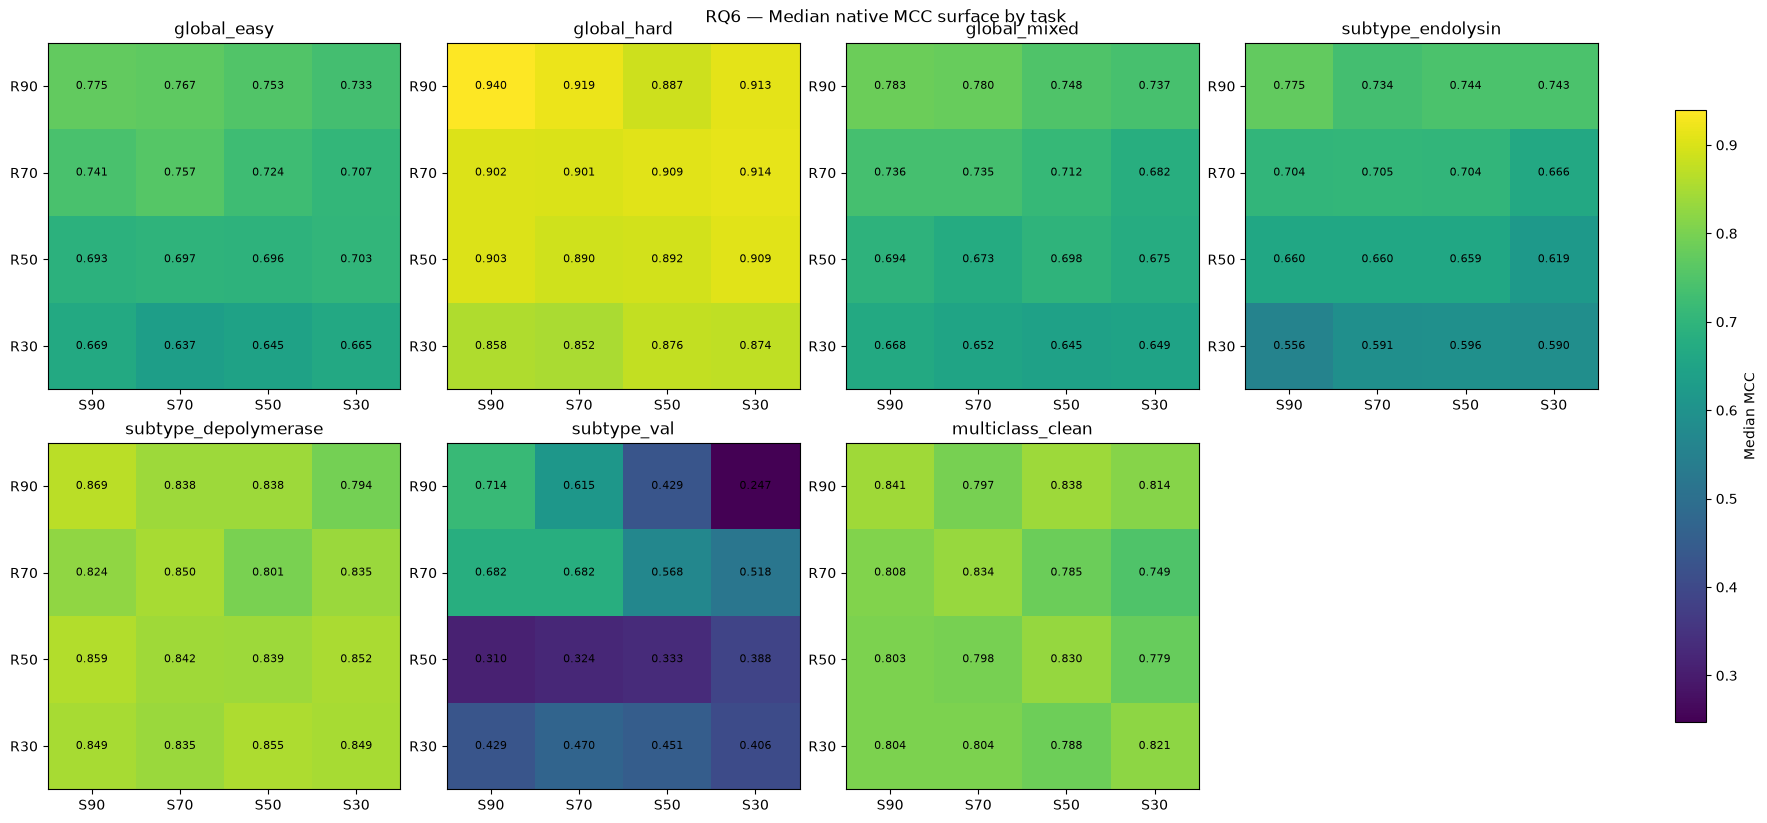

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq6_surface_geometry/figures/rq6_task_median_mcc_surfaces.png


In [5]:
def heatmap_grid(df, value_col, facet_col, facet_order, title, filename, value_label, symmetric=False):
    facets = [x for x in facet_order if x in df[facet_col].unique()]
    n = len(facets)
    ncols = min(4, max(1, n))
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 4.0 * nrows), squeeze=False, constrained_layout=True)
    axes = axes.ravel()

    vals = pd.to_numeric(df[value_col], errors="coerce")
    if symmetric:
        vmax = float(np.nanmax(np.abs(vals.to_numpy()))) if vals.notna().any() else 1.0
        vmin = -vmax
    else:
        vmin = float(vals.min())
        vmax = float(vals.max())

    image = None
    for ax, facet in zip(axes, facets):
        sub = df[df[facet_col].eq(facet)]
        mat = (
            sub.pivot(index="R", columns="S", values=value_col)
            .reindex(index=R_LEVELS, columns=S_LEVELS)
        )
        image = ax.imshow(mat.to_numpy(dtype=float), aspect="auto", vmin=vmin, vmax=vmax)
        ax.set_title(str(facet))
        ax.set_xticks(range(len(S_LEVELS)), [f"S{s}" for s in S_LEVELS])
        ax.set_yticks(range(len(R_LEVELS)), [f"R{r}" for r in R_LEVELS])
        for i in range(len(R_LEVELS)):
            for j in range(len(S_LEVELS)):
                val = mat.iloc[i, j]
                if pd.notna(val):
                    ax.text(j, i, f"{val:.3f}", ha="center", va="center", fontsize=8)

    for ax in axes[len(facets):]:
        ax.axis("off")

    fig.suptitle(title, y=1.01)
    if image is not None:
        cbar = fig.colorbar(image, ax=axes[:len(facets)].tolist(), shrink=0.82)
        cbar.set_label(value_label)
    path = FIG_DIR / filename
    fig.savefig(path, dpi=220, bbox_inches="tight")
    plt.show()
    print("Saved:", path)

heatmap_grid(
    task_surface,
    "mcc_median",
    "task",
    TASKS,
    "RQ6 — Median native MCC surface by task",
    "rq6_task_median_mcc_surfaces.png",
    "Median MCC",
    symmetric=False,
)

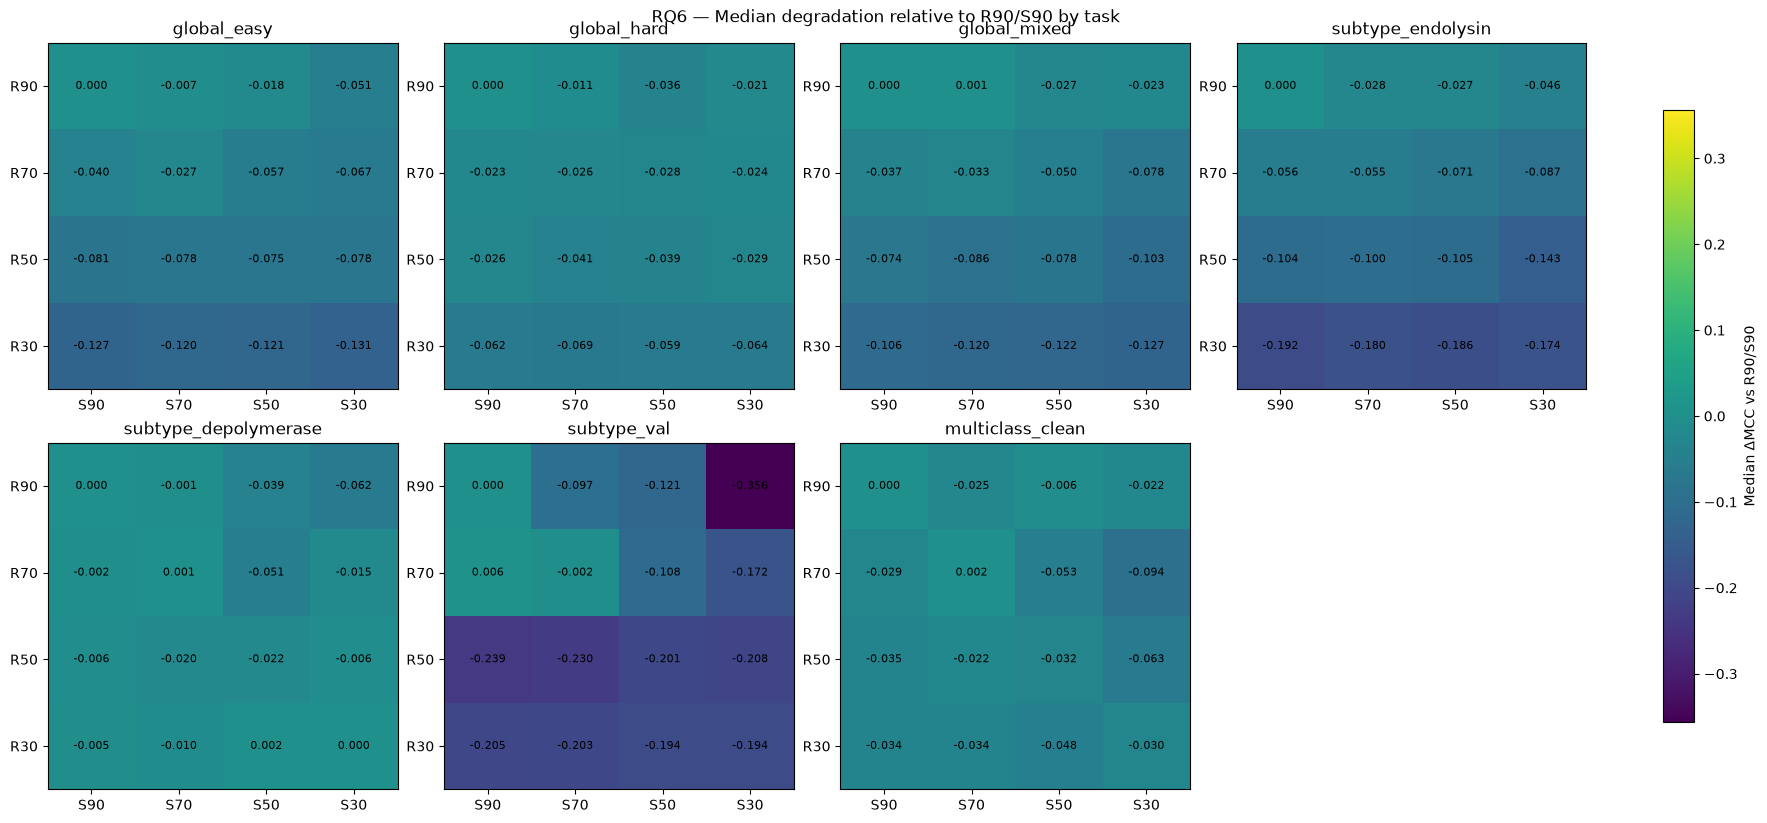

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq6_surface_geometry/figures/rq6_task_median_degradation_surfaces.png


In [6]:
heatmap_grid(
    task_surface,
    "delta_median",
    "task",
    TASKS,
    "RQ6 — Median degradation relative to R90/S90 by task",
    "rq6_task_median_degradation_surfaces.png",
    "Median ΔMCC vs R90/S90",
    symmetric=True,
)

## 4. Representation-level degradation geometry

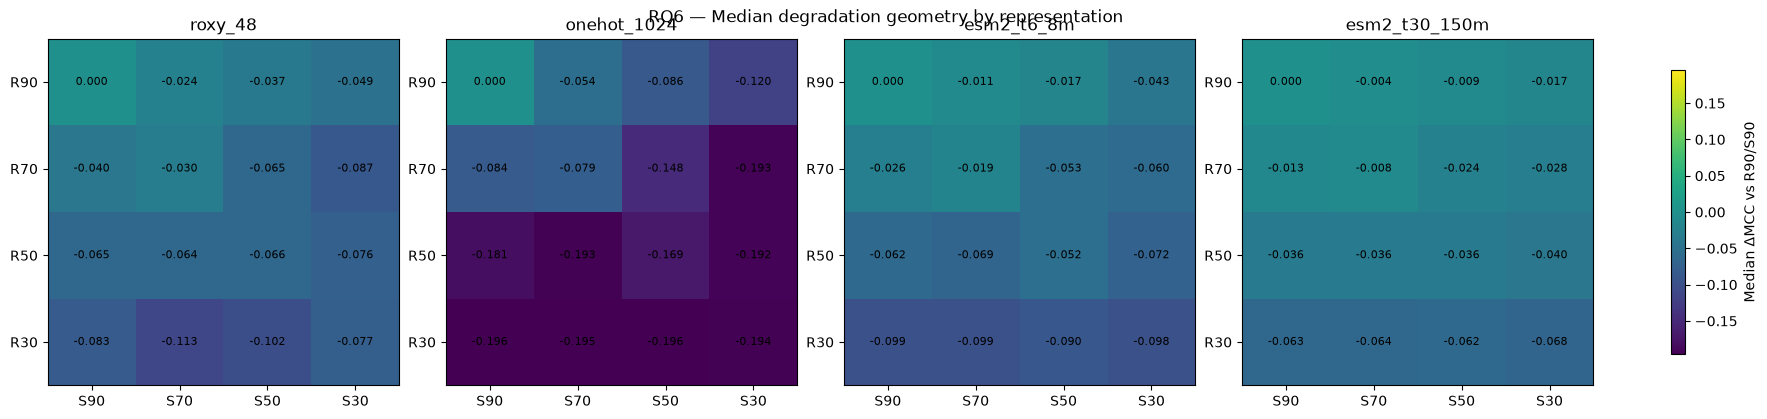

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq6_surface_geometry/figures/rq6_representation_median_degradation_surfaces.png


,representation,R,S,mcc_median,delta_median,loss_median,retention_median,n
0,esm2_t30_150m,30,30,0.880510,-0.067507,0.067507,0.929183,35
1,esm2_t30_150m,30,50,0.869106,-0.062048,0.062048,0.932522,35
2,esm2_t30_150m,30,70,0.869458,-0.064042,0.064042,0.932627,35
3,esm2_t30_150m,30,90,0.871548,-0.062750,0.062750,0.930186,35
4,esm2_t30_150m,50,30,0.905764,-0.040291,0.040291,0.954153,35
5,esm2_t30_150m,50,50,0.888367,-0.035923,0.035923,0.962457,35
6,esm2_t30_150m,50,70,0.887066,-0.035928,0.035928,0.962577,35
7,esm2_t30_150m,50,90,0.910344,-0.035520,0.035520,0.961780,35
8,esm2_t30_150m,70,30,0.911123,-0.028187,0.028187,0.968241,35
9,esm2_t30_150m,70,50,0.901327,-0.023984,0.023984,0.974557,35


In [7]:
rep_surface = (
    surface_cells.groupby(["representation", "R", "S"], as_index=False)
    .agg(
        mcc_median=(PRIMARY_METRIC, "median"),
        delta_median=("delta_from_R90S90", "median"),
        loss_median=("loss_from_R90S90", "median"),
        retention_median=("retention_fraction", "median"),
        n=(PRIMARY_METRIC, "size"),
    )
)

heatmap_grid(
    rep_surface,
    "delta_median",
    "representation",
    REPS,
    "RQ6 — Median degradation geometry by representation",
    "rq6_representation_median_degradation_surfaces.png",
    "Median ΔMCC vs R90/S90",
    symmetric=True,
)

display(rep_surface)

## 5. Surface-level geometric summaries for all model families

In [8]:
def adjacent_edge_table(group):
    lookup = {
        (int(row.R), int(row.S)): float(row.mcc)
        for row in group[["R", "S", PRIMARY_METRIC]].itertuples(index=False)
    }
    rows = []

    for s in S_LEVELS:
        for loose, strict in zip(R_LEVELS[:-1], R_LEVELS[1:]):
            a = lookup[(loose, s)]
            b = lookup[(strict, s)]
            rows.append({
                "axis": "R",
                "fixed_level": s,
                "from_level": loose,
                "to_level": strict,
                "delta_strict_minus_loose": b - a,
            })

    for r in R_LEVELS:
        for loose, strict in zip(S_LEVELS[:-1], S_LEVELS[1:]):
            a = lookup[(r, loose)]
            b = lookup[(r, strict)]
            rows.append({
                "axis": "S",
                "fixed_level": r,
                "from_level": loose,
                "to_level": strict,
                "delta_strict_minus_loose": b - a,
            })

    return pd.DataFrame(rows)


summary_rows = []
edge_rows = []

for keys, group in surface_cells.groupby(group_cols, sort=False):
    task, rep, alg = keys
    g = group.copy()
    base = float(g.loc[g["is_baseline"], PRIMARY_METRIC].iloc[0])
    strict = float(g.loc[g["is_strict_corner"], PRIMARY_METRIC].iloc[0])

    edges = adjacent_edge_table(g)
    edges["task"] = task
    edges["representation"] = rep
    edges["algorithm"] = alg
    edge_rows.append(edges)

    best_row = g.loc[g[PRIMARY_METRIC].idxmax()]
    worst_row = g.loc[g[PRIMARY_METRIC].idxmin()]

    edge_delta = edges["delta_strict_minus_loose"]
    loss = g["loss_from_R90S90"]

    summary_rows.append({
        "task": task,
        "representation": rep,
        "algorithm": alg,
        "baseline_mcc_R90S90": base,
        "strict_mcc_R30S30": strict,
        "strict_delta": strict - base,
        "strict_loss": base - strict,
        "strict_retention_fraction": strict / base if base > 0 else np.nan,
        "mean_mcc": g[PRIMARY_METRIC].mean(),
        "median_mcc": g[PRIMARY_METRIC].median(),
        "worst_mcc": g[PRIMARY_METRIC].min(),
        "best_mcc": g[PRIMARY_METRIC].max(),
        "surface_range": g[PRIMARY_METRIC].max() - g[PRIMARY_METRIC].min(),
        "mean_delta_from_baseline": g["delta_from_R90S90"].mean(),
        "median_delta_from_baseline": g["delta_from_R90S90"].median(),
        "mean_loss_from_baseline": loss.mean(),
        "median_loss_from_baseline": loss.median(),
        "max_loss_from_baseline": loss.max(),
        "q75_loss_from_baseline": loss.quantile(0.75),
        "fraction_cells_below_baseline": (g["delta_from_R90S90"] < -MONOTONIC_TOL).mean(),
        "fraction_cells_above_baseline": (g["delta_from_R90S90"] > MONOTONIC_TOL).mean(),
        "mean_adjacent_abs_change": edge_delta.abs().mean(),
        "median_adjacent_abs_change": edge_delta.abs().median(),
        "fraction_adjacent_nonincreasing": (edge_delta <= MONOTONIC_TOL).mean(),
        "fraction_adjacent_clear_decrease": (edge_delta < -MONOTONIC_TOL).mean(),
        "fraction_adjacent_clear_increase": (edge_delta > MONOTONIC_TOL).mean(),
        "best_R": int(best_row["R"]),
        "best_S": int(best_row["S"]),
        "worst_R": int(worst_row["R"]),
        "worst_S": int(worst_row["S"]),
    })

surface_summary = pd.DataFrame(summary_rows)
adjacent_edges = pd.concat(edge_rows, ignore_index=True)

assert len(surface_summary) == n_expected_surfaces
assert len(adjacent_edges) == n_expected_surfaces * 24, "Expected 24 adjacent edges per 4×4 surface."

print("Surface summaries:", len(surface_summary))
print("Adjacent directed edges:", len(adjacent_edges))
display(surface_summary.head())

Surface summaries: 140
Adjacent directed edges: 3360


,task,representation,algorithm,baseline_mcc_R90S90,strict_mcc_R30S30,strict_delta,strict_loss,strict_retention_fraction,mean_mcc,median_mcc,worst_mcc,best_mcc,surface_range,mean_delta_from_baseline,median_delta_from_baseline,mean_loss_from_baseline,median_loss_from_baseline,max_loss_from_baseline,q75_loss_from_baseline,fraction_cells_below_baseline,fraction_cells_above_baseline,mean_adjacent_abs_change,median_adjacent_abs_change,fraction_adjacent_nonincreasing,fraction_adjacent_clear_decrease,fraction_adjacent_clear_increase,best_R,best_S,worst_R,worst_S
0,global_easy,roxy_48,LR,0.511638,0.473778,-0.037860,0.037860,0.926002,0.482347,0.479575,0.449463,0.511638,0.062175,-0.029291,-0.032063,0.029291,0.032063,0.062175,0.041326,0.8125,0.0,0.020762,0.021389,0.666667,0.541667,0.333333,90,90,30,50
1,global_easy,roxy_48,RF,0.708529,0.537101,-0.171429,0.171429,0.758050,0.630261,0.625915,0.537101,0.710186,0.173086,-0.078268,-0.082615,0.078268,0.082615,0.171429,0.109222,0.8750,0.0,0.031618,0.030473,0.833333,0.666667,0.166667,90,70,30,30
2,global_easy,roxy_48,KNN,0.770957,0.569305,-0.201651,0.201651,0.738440,0.653812,0.652242,0.569305,0.770957,0.201651,-0.117145,-0.118715,0.117145,0.118715,0.201651,0.158835,0.9375,0.0,0.038133,0.035755,0.833333,0.750000,0.166667,90,90,30,30
3,global_easy,roxy_48,XGB,0.772730,0.640564,-0.132166,0.132166,0.828963,0.690156,0.687379,0.591684,0.772730,0.181046,-0.082574,-0.085350,0.082574,0.085350,0.181046,0.105497,0.9375,0.0,0.033683,0.024164,0.750000,0.708333,0.250000,90,90,30,70
4,global_easy,roxy_48,MLP,0.774161,0.633651,-0.140511,0.140511,0.818500,0.670811,0.651686,0.597200,0.774161,0.176961,-0.103351,-0.122475,0.103351,0.122475,0.176961,0.127864,0.9375,0.0,0.034989,0.034389,0.833333,0.625000,0.166667,90,90,30,70


### Geometry descriptors used here

- **Strict delta:** `M(R30,S30) − M(R90,S90)`.
- **Mean loss from baseline:** average `M(R90,S90) − M(R,S)` across the full 16-cell landscape.
- **Surface range:** best minus worst MCC anywhere on the landscape.
- **Adjacent absolute change:** local roughness across the 24 one-step edges of the 4×4 grid.
- **Adjacent non-increasing fraction:** fraction of one-step moves toward stricter R or S that do not improve by more than `0.005 MCC`.

These are descriptive geometry measures. They are **not** substitutes for the dedicated R-vs-S dominance, bootstrap, common-test, or deployment analyses.


## 6. How much performance survives at the strict corner?

In [9]:
strict_by_task = (
    surface_summary.groupby("task", as_index=False)
    .agg(
        n_surfaces=("strict_delta", "size"),
        baseline_mcc_median=("baseline_mcc_R90S90", "median"),
        strict_mcc_median=("strict_mcc_R30S30", "median"),
        strict_delta_median=("strict_delta", "median"),
        strict_delta_mean=("strict_delta", "mean"),
        strict_delta_q25=("strict_delta", lambda x: x.quantile(0.25)),
        strict_delta_q75=("strict_delta", lambda x: x.quantile(0.75)),
        retention_median=("strict_retention_fraction", "median"),
        mean_loss_median=("mean_loss_from_baseline", "median"),
        roughness_median=("mean_adjacent_abs_change", "median"),
        nonincreasing_fraction_median=("fraction_adjacent_nonincreasing", "median"),
    )
)

strict_by_rep = (
    surface_summary.groupby("representation", as_index=False)
    .agg(
        n_surfaces=("strict_delta", "size"),
        baseline_mcc_median=("baseline_mcc_R90S90", "median"),
        strict_mcc_median=("strict_mcc_R30S30", "median"),
        strict_delta_median=("strict_delta", "median"),
        retention_median=("strict_retention_fraction", "median"),
        mean_loss_median=("mean_loss_from_baseline", "median"),
        roughness_median=("mean_adjacent_abs_change", "median"),
        nonincreasing_fraction_median=("fraction_adjacent_nonincreasing", "median"),
    )
)

strict_by_alg = (
    surface_summary.groupby("algorithm", as_index=False)
    .agg(
        n_surfaces=("strict_delta", "size"),
        baseline_mcc_median=("baseline_mcc_R90S90", "median"),
        strict_mcc_median=("strict_mcc_R30S30", "median"),
        strict_delta_median=("strict_delta", "median"),
        retention_median=("strict_retention_fraction", "median"),
        mean_loss_median=("mean_loss_from_baseline", "median"),
        roughness_median=("mean_adjacent_abs_change", "median"),
    )
)

print("By task")
display(strict_by_task.sort_values("strict_delta_median"))
print("By representation")
display(strict_by_rep.sort_values("strict_delta_median"))
print("By algorithm")
display(strict_by_alg.sort_values("strict_delta_median"))

By task


,task,n_surfaces,baseline_mcc_median,strict_mcc_median,strict_delta_median,strict_delta_mean,strict_delta_q25,strict_delta_q75,retention_median,mean_loss_median,roughness_median,nonincreasing_fraction_median
6,subtype_val,20,0.714356,0.406358,-0.194032,-0.216452,-0.334161,-0.101703,0.658388,0.181366,0.101381,0.625000
5,subtype_endolysin,20,0.774572,0.590197,-0.174098,-0.195654,-0.226961,-0.110500,0.801279,0.097846,0.036160,0.875000
0,global_easy,20,0.774564,0.664537,-0.131290,-0.151215,-0.191727,-0.087508,0.844879,0.068502,0.027900,0.833333
2,global_mixed,20,0.783495,0.648663,-0.126944,-0.152134,-0.183095,-0.102010,0.846554,0.064999,0.028366,0.875000
1,global_hard,20,0.939674,0.873673,-0.063979,-0.069632,-0.079084,-0.054516,0.933253,0.031640,0.017445,0.791667
3,multiclass_clean,20,0.840622,0.820753,-0.030244,-0.028941,-0.054926,-0.018531,0.963631,0.034180,0.032445,0.666667
4,subtype_depolymerase,20,0.868501,0.849102,0.000493,0.003642,-0.029595,0.006875,1.000532,0.016551,0.024411,0.541667


By representation


,representation,n_surfaces,baseline_mcc_median,strict_mcc_median,strict_delta_median,retention_median,mean_loss_median,roughness_median,nonincreasing_fraction_median
2,onehot_1024,35,0.636875,0.390374,-0.194030,0.667987,0.150575,0.041534,0.791667
1,esm2_t6_8m,35,0.884309,0.781808,-0.098176,0.888435,0.053233,0.026759,0.750000
3,roxy_48,35,0.774161,0.615759,-0.077379,0.901589,0.055427,0.033683,0.666667
0,esm2_t30_150m,35,0.929346,0.880510,-0.067507,0.929183,0.034569,0.018547,0.833333


By algorithm


,algorithm,n_surfaces,baseline_mcc_median,strict_mcc_median,strict_delta_median,retention_median,mean_loss_median,roughness_median
3,RF,28,0.792303,0.694752,-0.106541,0.877932,0.051132,0.029753
0,KNN,28,0.855143,0.752852,-0.099096,0.877808,0.062618,0.034966
4,XGB,28,0.870278,0.759450,-0.094568,0.884961,0.054152,0.028868
2,MLP,28,0.874999,0.785579,-0.080500,0.910905,0.041376,0.030568
1,LR,28,0.764928,0.692668,-0.067233,0.908997,0.038767,0.024668


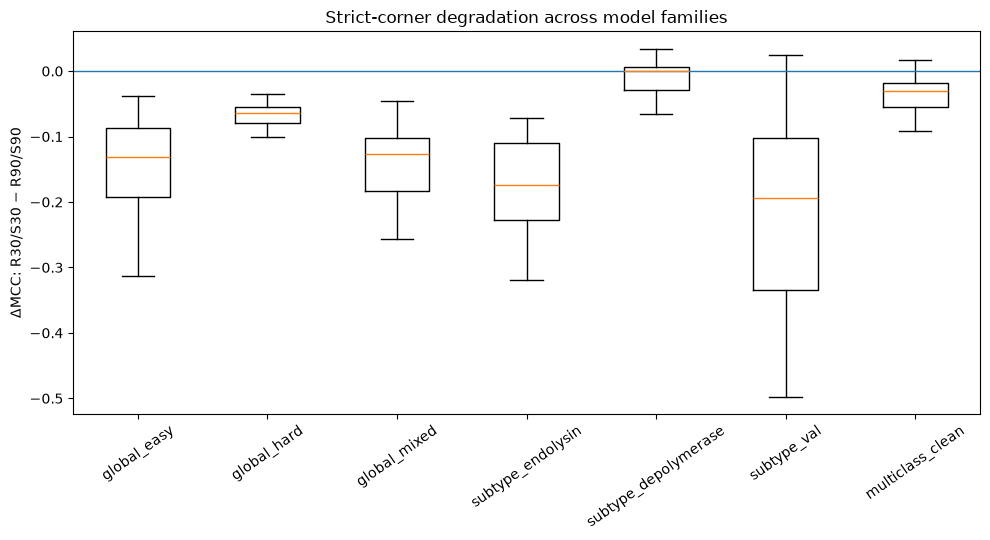

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq6_surface_geometry/figures/rq6_strict_corner_delta_by_task.png


In [10]:
fig, ax = plt.subplots(figsize=(10, 5.5))
data = [
    surface_summary.loc[surface_summary["task"].eq(task), "strict_delta"].dropna().to_numpy()
    for task in TASKS
]
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, len(TASKS) + 1), TASKS)
ax.axhline(0.0, linewidth=1)
ax.set_ylabel("ΔMCC: R30/S30 − R90/S90")
ax.set_title("Strict-corner degradation across model families")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
path = FIG_DIR / "rq6_strict_corner_delta_by_task.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)

## 7. Best/worst-cell topology across the complete landscape

In [11]:
best_cells = (
    surface_summary.assign(cell=lambda x: "R" + x["best_R"].astype(str) + "_S" + x["best_S"].astype(str))
    ["cell"].value_counts().rename_axis("cell").rename("n_surfaces").reset_index()
)
best_cells["fraction"] = best_cells["n_surfaces"] / len(surface_summary)

worst_cells = (
    surface_summary.assign(cell=lambda x: "R" + x["worst_R"].astype(str) + "_S" + x["worst_S"].astype(str))
    ["cell"].value_counts().rename_axis("cell").rename("n_surfaces").reset_index()
)
worst_cells["fraction"] = worst_cells["n_surfaces"] / len(surface_summary)

print("Most frequent BEST cells")
display(best_cells.head(16))
print("Most frequent WORST cells")
display(worst_cells.head(16))

Most frequent BEST cells


,cell,n_surfaces,fraction
0,R90_S90,68,0.485714
1,R90_S70,24,0.171429
2,R70_S70,10,0.071429
3,R70_S90,9,0.064286
4,R90_S50,8,0.057143
5,R30_S30,5,0.035714
6,R50_S30,4,0.028571
7,R90_S30,3,0.021429
8,R30_S50,3,0.021429
9,R30_S70,2,0.014286


Most frequent WORST cells


,cell,n_surfaces,fraction
0,R90_S30,23,0.164286
1,R30_S70,20,0.142857
2,R30_S30,19,0.135714
3,R30_S50,18,0.128571
4,R70_S30,18,0.128571
5,R30_S90,17,0.121429
6,R70_S50,6,0.042857
7,R50_S30,4,0.028571
8,R50_S50,4,0.028571
9,R90_S70,4,0.028571


## 8. Local surface smoothness and directional consistency

In [12]:
edge_summary = (
    adjacent_edges.groupby("axis", as_index=False)
    .agg(
        n=("delta_strict_minus_loose", "size"),
        median_delta=("delta_strict_minus_loose", "median"),
        mean_delta=("delta_strict_minus_loose", "mean"),
        median_abs_delta=("delta_strict_minus_loose", lambda x: x.abs().median()),
        mean_abs_delta=("delta_strict_minus_loose", lambda x: x.abs().mean()),
        fraction_clear_decrease=("delta_strict_minus_loose", lambda x: (x < -MONOTONIC_TOL).mean()),
        fraction_near_flat=("delta_strict_minus_loose", lambda x: (x.abs() <= MONOTONIC_TOL).mean()),
        fraction_clear_increase=("delta_strict_minus_loose", lambda x: (x > MONOTONIC_TOL).mean()),
    )
)

display(edge_summary)

edge_by_task = (
    adjacent_edges.groupby(["task", "axis"], as_index=False)
    .agg(
        median_delta=("delta_strict_minus_loose", "median"),
        median_abs_delta=("delta_strict_minus_loose", lambda x: x.abs().median()),
        fraction_clear_decrease=("delta_strict_minus_loose", lambda x: (x < -MONOTONIC_TOL).mean()),
        fraction_clear_increase=("delta_strict_minus_loose", lambda x: (x > MONOTONIC_TOL).mean()),
    )
)

display(edge_by_task)

,axis,n,median_delta,mean_delta,median_abs_delta,mean_abs_delta,fraction_clear_decrease,fraction_near_flat,fraction_clear_increase
0,R,1680,-0.022234,-0.024390,0.032388,0.049891,0.675000,0.098214,0.226786
1,S,1680,-0.005203,-0.012898,0.015824,0.029691,0.504167,0.208929,0.286905


,task,axis,median_delta,median_abs_delta,fraction_clear_decrease,fraction_clear_increase
0,global_easy,R,-0.033522,0.035823,0.883333,0.079167
1,global_easy,S,-0.005740,0.013973,0.516667,0.233333
2,global_hard,R,-0.017470,0.019187,0.720833,0.116667
3,global_hard,S,-0.003036,0.011011,0.454167,0.333333
4,global_mixed,R,-0.034613,0.035444,0.879167,0.054167
5,global_mixed,S,-0.008030,0.012939,0.600000,0.237500
6,multiclass_clean,R,-0.007648,0.028187,0.533333,0.387500
7,multiclass_clean,S,-0.007251,0.027089,0.525000,0.304167
8,subtype_depolymerase,R,0.005346,0.020879,0.333333,0.504167
9,subtype_depolymerase,S,-0.000067,0.018845,0.437500,0.375000


The edge summaries are included to describe **surface smoothness/irregularity**, not to replace RQ5. RQ5 remains the canonical analysis for whether R or S is the dominant driver. RQ6 only asks whether movement across the two-dimensional grid tends to produce consistent local degradation or frequent reversals.


## 9. Cross-metric concordance of degradation geometry

In [13]:
def detect_prevalence(df):
    candidates = [
        "test_prevalence",
        "prevalence",
        "positive_prevalence",
        "class_prevalence",
    ]
    for c in candidates:
        if c in df.columns:
            return pd.to_numeric(df[c], errors="coerce"), c

    if {"n_positive", "n_test"} <= set(df.columns):
        pos = pd.to_numeric(df["n_positive"], errors="coerce")
        n = pd.to_numeric(df["n_test"], errors="coerce")
        return pos / n, "derived_from_n_positive_n_test"

    if {"tp", "fn", "tn", "fp"} <= set(df.columns):
        pos = pd.to_numeric(df["tp"], errors="coerce") + pd.to_numeric(df["fn"], errors="coerce")
        n = pos + pd.to_numeric(df["tn"], errors="coerce") + pd.to_numeric(df["fp"], errors="coerce")
        return pos / n, "derived_from_confusion_counts"

    return pd.Series(np.nan, index=df.index), None

metric_long_parts = []
metric_concordance_rows = []

# Binary: prevalence-normalized AP skill if AP and prevalence are available.
if "ap" in master.columns:
    prevalence, prevalence_source = detect_prevalence(master)
    master["_rq6_prevalence"] = prevalence
    denom = 1.0 - master["_rq6_prevalence"]
    master["_rq6_ap_skill"] = np.where(
        denom > 0,
        (pd.to_numeric(master["ap"], errors="coerce") - master["_rq6_prevalence"]) / denom,
        np.nan,
    )

    b = master[master["task"].isin(BINARY_TASKS)].copy()
    bbase = (
        b.loc[b["R"].eq(90) & b["S"].eq(90), group_cols + ["_rq6_ap_skill"]]
        .rename(columns={"_rq6_ap_skill": "baseline_secondary"})
    )
    b = b.merge(bbase, on=group_cols, how="left", validate="many_to_one")
    b["secondary_delta"] = b["_rq6_ap_skill"] - b["baseline_secondary"]
    b = b.merge(
        surface_cells[group_cols + ["R", "S", "delta_from_R90S90"]],
        on=group_cols + ["R", "S"],
        how="left",
        validate="one_to_one",
    )
    valid = b[["delta_from_R90S90", "secondary_delta"]].dropna()
    if len(valid) >= 3:
        metric_concordance_rows.append({
            "scope": "binary_all",
            "secondary_metric": "AP_skill",
            "n_cells": len(valid),
            "spearman_delta_concordance": valid["delta_from_R90S90"].corr(valid["secondary_delta"], method="spearman"),
            "pearson_delta_concordance": valid["delta_from_R90S90"].corr(valid["secondary_delta"], method="pearson"),
            "prevalence_source": prevalence_source,
        })

    for task, tg in b.groupby("task"):
        valid = tg[["delta_from_R90S90", "secondary_delta"]].dropna()
        if len(valid) >= 3:
            metric_concordance_rows.append({
                "scope": task,
                "secondary_metric": "AP_skill",
                "n_cells": len(valid),
                "spearman_delta_concordance": valid["delta_from_R90S90"].corr(valid["secondary_delta"], method="spearman"),
                "pearson_delta_concordance": valid["delta_from_R90S90"].corr(valid["secondary_delta"], method="pearson"),
                "prevalence_source": prevalence_source,
            })

# Multiclass: macro-F1 if available.
if "macro_f1" in master.columns and "multiclass_clean" in set(master["task"]):
    m = master[master["task"].eq("multiclass_clean")].copy()
    m["macro_f1"] = pd.to_numeric(m["macro_f1"], errors="coerce")
    mbase = (
        m.loc[m["R"].eq(90) & m["S"].eq(90), group_cols + ["macro_f1"]]
        .rename(columns={"macro_f1": "baseline_secondary"})
    )
    m = m.merge(mbase, on=group_cols, how="left", validate="many_to_one")
    m["secondary_delta"] = m["macro_f1"] - m["baseline_secondary"]
    m = m.merge(
        surface_cells[group_cols + ["R", "S", "delta_from_R90S90"]],
        on=group_cols + ["R", "S"],
        how="left",
        validate="one_to_one",
    )
    valid = m[["delta_from_R90S90", "secondary_delta"]].dropna()
    if len(valid) >= 3:
        metric_concordance_rows.append({
            "scope": "multiclass_clean",
            "secondary_metric": "macro_f1",
            "n_cells": len(valid),
            "spearman_delta_concordance": valid["delta_from_R90S90"].corr(valid["secondary_delta"], method="spearman"),
            "pearson_delta_concordance": valid["delta_from_R90S90"].corr(valid["secondary_delta"], method="pearson"),
            "prevalence_source": "not_applicable",
        })

metric_concordance = pd.DataFrame(metric_concordance_rows)
if metric_concordance.empty:
    print("Secondary metric concordance is not estimable from available Stage12A columns.")
else:
    display(metric_concordance)

,scope,secondary_metric,n_cells,spearman_delta_concordance,pearson_delta_concordance,prevalence_source
0,binary_all,AP_skill,1920,0.858440,0.868758,prevalence
1,global_easy,AP_skill,320,0.954794,0.931267,prevalence
2,global_hard,AP_skill,320,0.786855,0.805066,prevalence
3,global_mixed,AP_skill,320,0.963509,0.947006,prevalence
4,subtype_depolymerase,AP_skill,320,0.561142,0.622081,prevalence
5,subtype_endolysin,AP_skill,320,0.961632,0.927291,prevalence
6,subtype_val,AP_skill,320,0.764460,0.752469,prevalence
7,multiclass_clean,macro_f1,320,0.757528,0.747472,not_applicable


## 10. Compact key-result tables for downstream synthesis

In [14]:
global_summary = pd.DataFrame([{
    "n_surfaces": len(surface_summary),
    "n_cells": len(surface_cells),
    "median_baseline_mcc": surface_summary["baseline_mcc_R90S90"].median(),
    "median_strict_mcc": surface_summary["strict_mcc_R30S30"].median(),
    "median_strict_delta": surface_summary["strict_delta"].median(),
    "median_strict_retention_fraction": surface_summary["strict_retention_fraction"].median(),
    "median_mean_loss_from_baseline": surface_summary["mean_loss_from_baseline"].median(),
    "median_surface_range": surface_summary["surface_range"].median(),
    "median_surface_roughness": surface_summary["mean_adjacent_abs_change"].median(),
    "median_adjacent_nonincreasing_fraction": surface_summary["fraction_adjacent_nonincreasing"].median(),
}])

display(global_summary)

most_strict_task = strict_by_task.sort_values("strict_delta_median").iloc[0]
least_strict_task = strict_by_task.sort_values("strict_delta_median", ascending=False).iloc[0]
most_robust_rep = strict_by_rep.sort_values("strict_delta_median", ascending=False).iloc[0]

print(f"Global median strict ΔMCC: {global_summary.iloc[0]['median_strict_delta']:.4f}")
print(f"Largest median strict-corner loss by task: {most_strict_task['task']} ({most_strict_task['strict_delta_median']:.4f})")
print(f"Smallest / most favorable median strict-corner change by task: {least_strict_task['task']} ({least_strict_task['strict_delta_median']:.4f})")
print(f"Most favorable representation by median strict ΔMCC: {most_robust_rep['representation']} ({most_robust_rep['strict_delta_median']:.4f})")

,n_surfaces,n_cells,median_baseline_mcc,median_strict_mcc,median_strict_delta,median_strict_retention_fraction,median_mean_loss_from_baseline,median_surface_range,median_surface_roughness,median_adjacent_nonincreasing_fraction
0,140,2240,0.833678,0.73848,-0.084068,0.90256,0.051929,0.131021,0.028868,0.75


Global median strict ΔMCC: -0.0841
Largest median strict-corner loss by task: subtype_val (-0.1940)
Smallest / most favorable median strict-corner change by task: subtype_depolymerase (0.0005)
Most favorable representation by median strict ΔMCC: esm2_t30_150m (-0.0675)


## 11. Export canonical RQ6 outputs

In [15]:
exports = {
    "rq6_surface_cells.tsv": surface_cells,
    "rq6_surface_summary.tsv": surface_summary,
    "rq6_adjacent_edges.tsv": adjacent_edges,
    "rq6_task_surface_cells.tsv": task_surface,
    "rq6_representation_surface_cells.tsv": rep_surface,
    "rq6_task_geometry_summary.tsv": strict_by_task,
    "rq6_representation_geometry_summary.tsv": strict_by_rep,
    "rq6_algorithm_geometry_summary.tsv": strict_by_alg,
    "rq6_best_cells.tsv": best_cells,
    "rq6_worst_cells.tsv": worst_cells,
    "rq6_edge_summary.tsv": edge_summary,
    "rq6_edge_summary_by_task.tsv": edge_by_task,
    "rq6_metric_concordance.tsv": metric_concordance,
    "rq6_global_summary.tsv": global_summary,
}

for filename, df in exports.items():
    path = RQ6_OUT / filename
    df.to_csv(path, sep="\t", index=False)
    print(f"Wrote {filename}: {len(df)} rows")

manifest = {
    "rq": "RQ6",
    "question": "full geometry of M(R,S) and degradation from R90/S90",
    "primary_metric": PRIMARY_METRIC,
    "R_levels": R_LEVELS,
    "S_levels": S_LEVELS,
    "n_input_rows": int(len(master)),
    "n_surfaces": int(len(surface_summary)),
    "n_cells_per_surface": 16,
    "native_test_warning": "R/S contrasts are factorial native-test contrasts, not automatically entity-level paired.",
    "training_performed": False,
    "bootstrap_performed": False,
    "prediction_regeneration_performed": False,
}

with open(RQ6_OUT / "rq6_manifest.json", "w", encoding="utf-8") as fh:
    json.dump(manifest, fh, indent=2)

print("Wrote rq6_manifest.json")

Wrote rq6_surface_cells.tsv: 2240 rows
Wrote rq6_surface_summary.tsv: 140 rows
Wrote rq6_adjacent_edges.tsv: 3360 rows
Wrote rq6_task_surface_cells.tsv: 112 rows
Wrote rq6_representation_surface_cells.tsv: 64 rows
Wrote rq6_task_geometry_summary.tsv: 7 rows
Wrote rq6_representation_geometry_summary.tsv: 4 rows
Wrote rq6_algorithm_geometry_summary.tsv: 5 rows
Wrote rq6_best_cells.tsv: 13 rows
Wrote rq6_worst_cells.tsv: 14 rows
Wrote rq6_edge_summary.tsv: 2 rows
Wrote rq6_edge_summary_by_task.tsv: 14 rows
Wrote rq6_metric_concordance.tsv: 8 rows
Wrote rq6_global_summary.tsv: 1 rows
Wrote rq6_manifest.json


## 12. Execution gates

In [16]:
required_exports = [
    "rq6_surface_cells.tsv",
    "rq6_surface_summary.tsv",
    "rq6_adjacent_edges.tsv",
    "rq6_task_surface_cells.tsv",
    "rq6_representation_surface_cells.tsv",
    "rq6_task_geometry_summary.tsv",
    "rq6_representation_geometry_summary.tsv",
    "rq6_algorithm_geometry_summary.tsv",
    "rq6_best_cells.tsv",
    "rq6_worst_cells.tsv",
    "rq6_edge_summary.tsv",
    "rq6_edge_summary_by_task.tsv",
    "rq6_metric_concordance.tsv",
    "rq6_global_summary.tsv",
    "rq6_manifest.json",
]

assert len(master) == n_expected_rows
assert len(surface_cells) == n_expected_rows
assert len(surface_summary) == n_expected_surfaces
assert surface_cells.groupby(group_cols).size().eq(16).all()
assert surface_cells.loc[surface_cells["is_baseline"], "delta_from_R90S90"].abs().max() < 1e-12
assert surface_cells.groupby(group_cols)["is_strict_corner"].sum().eq(1).all()
assert len(adjacent_edges) == n_expected_surfaces * 24
assert surface_summary["strict_delta"].notna().all()
assert surface_summary["mean_adjacent_abs_change"].notna().all()
assert all((RQ6_OUT / f).is_file() for f in required_exports)

figure_files = sorted(p.name for p in FIG_DIR.glob("*.png"))
assert len(figure_files) >= 4, f"Expected at least 4 RQ6 figures, found {figure_files}"

print("RQ6_EXECUTION_GATES_OK")
print("Input rows:", len(master))
print("Complete surfaces:", len(surface_summary))
print("Exports:", len(required_exports))
print("Figures:", figure_files)
print("\nInterpretation status: execution gates passed. Real-data scientific PASS should only be assigned after the executed notebook and outputs are inspected.")

RQ6_EXECUTION_GATES_OK
Input rows: 2240
Complete surfaces: 140
Exports: 15
Figures: ['rq6_representation_median_degradation_surfaces.png', 'rq6_strict_corner_delta_by_task.png', 'rq6_task_median_degradation_surfaces.png', 'rq6_task_median_mcc_surfaces.png']

Interpretation status: execution gates passed. Real-data scientific PASS should only be assigned after the executed notebook and outputs are inspected.


## RQ6 hand-off to later questions

RQ6 should leave the project with a canonical geometric representation of every supervised `R×S` landscape:

- the original `M(R,S)` surface;
- baseline-relative `D(R,S)`;
- strict-corner retention;
- full-surface degradation burden;
- best/worst topology;
- local roughness and directional consistency;
- cross-metric concordance where estimable.

These outputs are designed to be consumed downstream without reopening Stage12A:

- **RQ17:** robustness synthesis;
- **RQ20:** stepwise breakpoint/regime classification;
- **RQ21:** mixed joint-strictness trajectories;
- **RQ25:** final generalization-regime synthesis;
- **RQ26:** deployment-oriented Top-K selection.
